# Reply delay and delta rate

**How does the rate of verified OP deltas vary with the time from the OP post to the opening reply?** The denominator is eligible top-level challenger replies in the branch-level training data. Every included reply has the same seven-day outcome follow-up.

The primary window is the seven days immediately after the reply opens. The sensitivity window starts one hour after the reply opens and follows replies still at risk for the next seven days. The one-hour observation landmark changes which deltas and replies count. Reply delay itself is measured from the OP post in both views. The primary events are verified first OP awards within seven days of opening.

Eligibility requires complete follow-up and usable timestamps. The archived window rules exclude incomplete parent paths and ambiguous awards when they can affect the outcome. The [analysis script](reply_delay_delta_curve/analyze_reply_delay_delta_curve.py) validates these rules against all rows in the saved one-hour and 24-hour branch cohorts. This analysis uses the training data.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
DATA = REPO / "project/data/processed"
RUNS = DATA / "reply-delay-delta-curve"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
assert report["split"] == "train"
curve = pd.read_parquet(report_path.parent / "delay_curve.parquet")
cohorts = pd.DataFrame(report["cohorts"]).T.rename(
    index={"0": "From opening", "1": "After one hour"},
)
cohorts["Delta rate (%)"] = 100 * cohorts["deltas"] / cohorts["replies"]
display(cohorts.round(3))

,eligible_before_delay_check,missing_delay,replies,discussions,deltas,Delta rate (%)
From opening,213563,0,213563,18044,6131,2.871
After one hour,211192,0,211192,18024,3779,1.789


## Branch-level rate and eligible volume

Bins show hours in the first day and days thereafter. The bins have unequal durations and equal visual spacing. The lower panel gives the denominator for the primary rate in each bin. Intervals use 1,000 bootstrap samples of whole OP discussions.

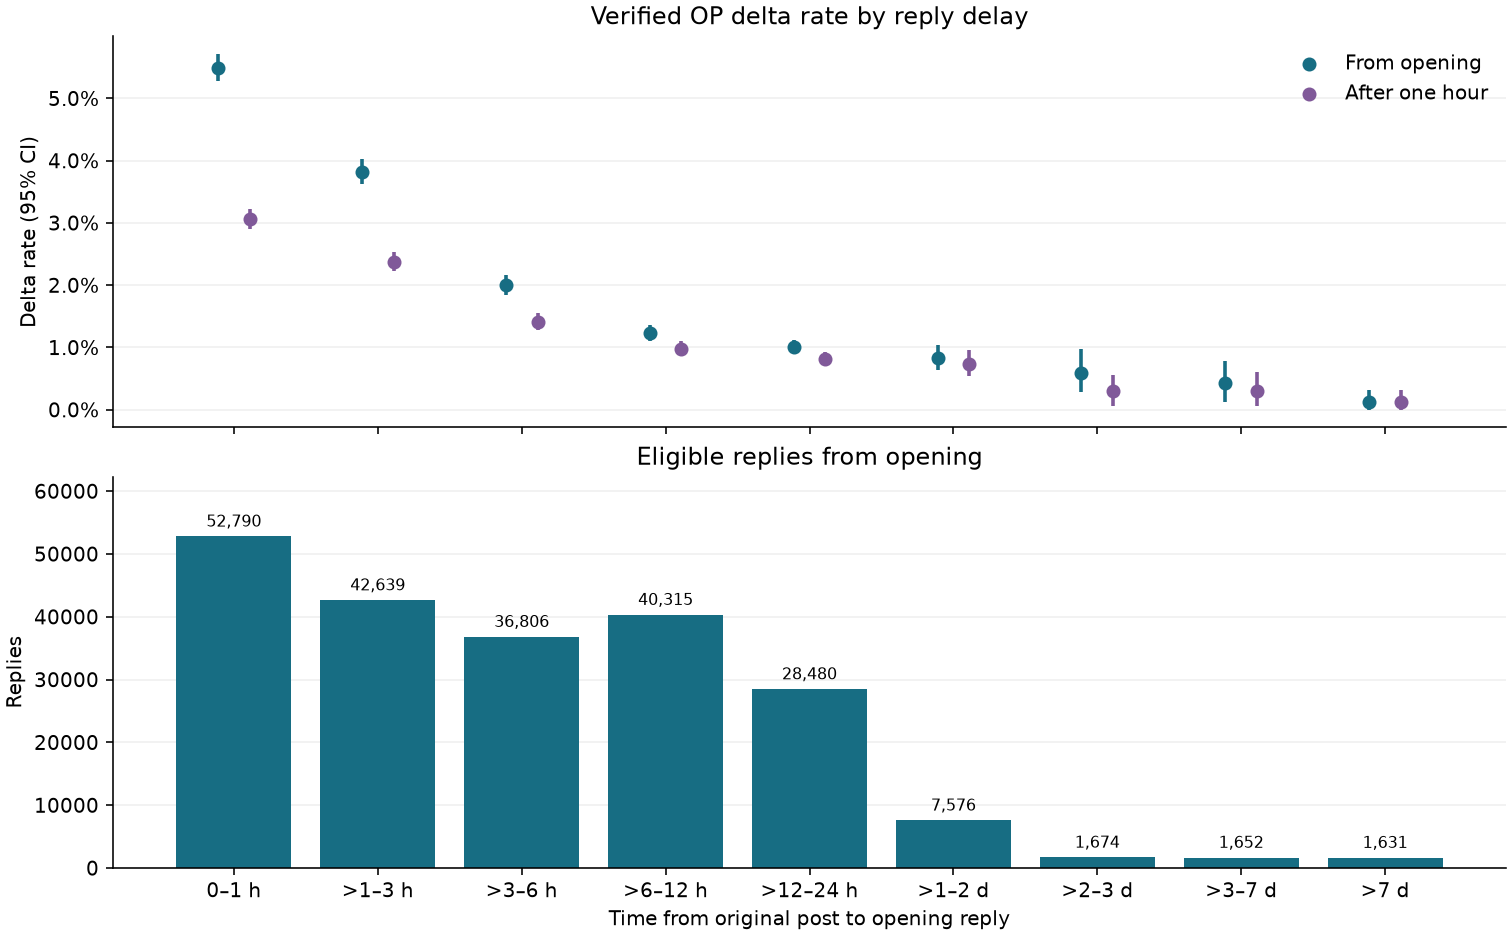

replies  deltas  Delta rate (%)  95% CI lower (%)  95% CI upper (%)
Window         delay_bin                                                                     
From opening   0–1 h        52790    2899           5.492             5.271             5.712
               >1–3 h       42639    1631           3.825             3.617             4.022
               >3–6 h       36806     736           2.000             1.849             2.164
               >6–12 h      40315     498           1.235             1.106             1.365
               >12–24 h     28480     285           1.001             0.888             1.121
               >1–2 d        7576      63           0.832             0.638             1.043
               >2–3 d        1674      10           0.597             0.291             0.977
               >3–7 d        1652       7           0.424             0.122             0.776
               >7 d          1631       2           0.123             0.000             0.309
After one hour 0–1 h        51465    1575           3.060             2.897             3.228
               >1–3 h       41998     996           2.372             2.224             2.529
               >3–6 h       36579     515           1.408             1.278             1.551
               >6–12 h      40209     395           0.982             0.871             1.099
               >12–24 h     28424     230           0.809             0.709             0.924
               >1–2 d        7568      56           0.740             0.545             0.956
               >2–3 d        1668       5           0.300             0.060             0.564
               >3–7 d        1650       5           0.303             0.062             0.599
               >7 d          1631       2           0.123             0.000             0.317

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

base = curve.loc[curve["observation_hours"].eq(0)].set_index("delay_bin")
landmark = curve.loc[curve["observation_hours"].eq(1)].set_index("delay_bin")
x = np.arange(len(base))
fig, (rate_ax, count_ax) = plt.subplots(2, 1, figsize=(10.5, 6.5), sharex=True, layout="constrained")
for group, offset, label, color in (
    (base, -0.11, "From opening", "#176d83"),
    (landmark, 0.11, "After one hour", "#805999"),
):
    rate_ax.vlines(x + offset, group["ci_lower"], group["ci_upper"], color=color, lw=1.8)
    rate_ax.scatter(x + offset, group["delta_rate"], color=color, label=label, zorder=3)
rate_ax.yaxis.set_major_formatter(PercentFormatter(1))
rate_ax.set(title="Verified OP delta rate by reply delay", ylabel="Delta rate (95% CI)")
rate_ax.legend(frameon=False)

bars = count_ax.bar(x, base["replies"], color="#176d83")
count_ax.bar_label(bars, labels=[f"{n:,}" for n in base["replies"]], padding=3, fontsize=8)
count_ax.set_xticks(x, base.index)
count_ax.set(title="Eligible replies from opening", ylabel="Replies", xlabel="Time from original post to opening reply")
count_ax.margins(y=0.18)
for ax in (rate_ax, count_ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()

table = pd.concat({"From opening": base, "After one hour": landmark}, names=["Window"])
for field in ("delta_rate", "ci_lower", "ci_upper"):
    table[field] *= 100
display(table[["replies", "deltas", "delta_rate", "ci_lower", "ci_upper"]].rename(columns={
    "delta_rate": "Delta rate (%)", "ci_lower": "95% CI lower (%)", "ci_upper": "95% CI upper (%)",
}).round(3))

## Earlier reply in the published pairs

The unit here is a matched pair. The rate is the share of pairs won by the earlier opening in each time gap. It differs from the branch-level probability above, whose denominator is all eligible replies.

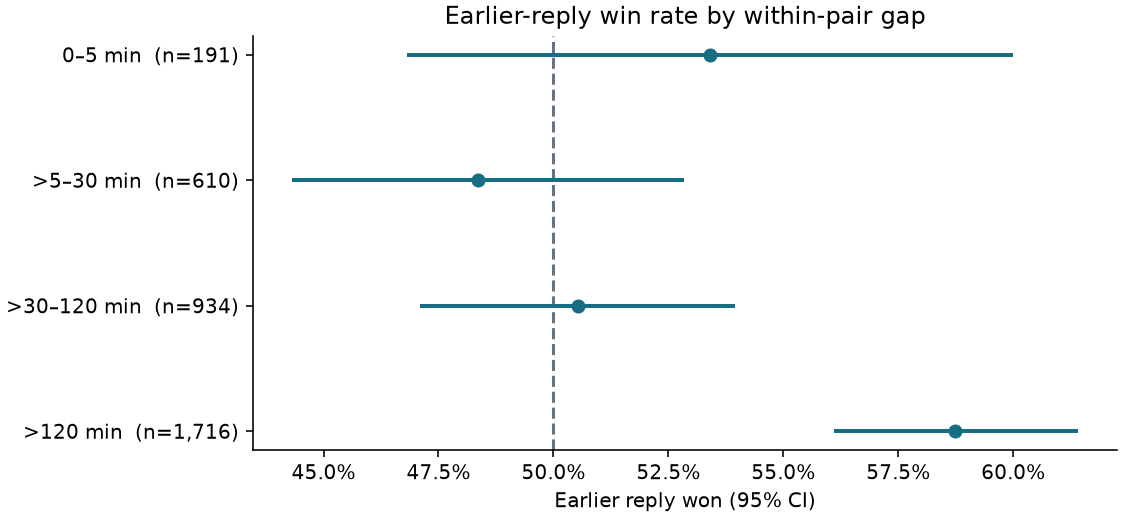

In [3]:
PAIRED_RUN = "20261120T215308951157Z"
pair_report = json.loads((DATA / "linguistic-features/reply-timing" / PAIRED_RUN / "results.json").read_text())
assert pair_report["split"] == "train"
groups = pd.DataFrame(pair_report["by_gap"]).T
groups[["lower", "upper"]] = pd.DataFrame(groups["ci_95"].tolist(), index=groups.index)
positions = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(7.8, 3.6), layout="constrained")
ax.axvline(0.5, linestyle="--", color="#63748a")
ax.hlines(positions, groups["lower"], groups["upper"], color="#176d83", lw=2)
ax.scatter(groups["winner_higher_rate"], positions, color="#176d83", zorder=3)
ax.set_yticks(positions, [f"{gap}  (n={row['pairs']:,.0f})" for gap, row in groups.iterrows()])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Earlier-reply win rate by within-pair gap", xlabel="Earlier reply won (95% CI)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Continuous delay versus candidate thresholds

Compare timing alone using logistic regression on the primary branch cohort in three training folds grouped by OP discussion. The continuous model uses `log1p(delay in minutes)`. Each threshold model uses a single indicator for replies posted past 6, 24, or 72 hours. All four models evaluate the same eligible replies. These thresholds change the feature representation. An inclusion cutoff would instead change the population and would require a separate trade-off analysis.

In [4]:
comparison = pd.read_csv(report_path.parent / "delay_encoding_cv.csv").set_index("encoding")
display(comparison.round(5))

,roc_auc,average_precision,log_loss
encoding,,,
Continuous log1p(minutes),0.68268,0.04937,0.12503
Delay > 6 h,0.62254,0.03857,0.12607
Delay > 24 h,0.52312,0.03006,0.12944
Delay > 72 h,0.50708,0.02911,0.12992
